# k-NN V9

For this experiment, I wanted to see if using a larger k would improve sentiment accuracy. Since k=20 worked best in V8, I tested some higher values using the same training and validation samples.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

k_values = [20, 30, 50, 75, 100]


I started by loading the sentiment dataset and using the same split as V8.

In [2]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
X_train = X_train[:8000]
y_train = y_train[:8000]
assert X_train.shape == (8000, 768)
assert X_val.shape == (2400, 768)
result_dir = project_root / "results" / "sentiment"
v8_summary = pd.read_csv(result_dir / "knn_v8_summary.csv")
v8_baseline = v8_summary.loc[v8_summary["k"] == 20].iloc[0]
v8_validation = pd.read_csv(result_dir / "knn_v8_validation.csv")
assert v8_baseline["training_samples"] == 8000
assert v8_baseline["validation_samples"] == 2400
assert v8_baseline["distance_metric"] == "euclidean"
assert v8_baseline["voting_method"] == "majority"
assert not v8_baseline["normalized"]
assert v8_validation["validation_index"].tolist() == list(range(2400))
assert v8_validation["actual_label"].tolist() == y_val.tolist()
print("Sentiment: 8000 training samples, 2400 validation samples")


Sentiment: 8000 training samples, 2400 validation samples


Then I tested the different k values and compared their accuracies.

In [3]:
rows = []
validation_predictions = {}
for k in k_values:
    clf = KNNClassifier(k=k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(X_train, y_train)
    start = perf_counter()
    y_pred = clf.predict(X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, y_val)) / len(y_val)
    validation_predictions[k] = y_pred
    if k == 20:
        assert abs(accuracy - 0.5629166666666666) <= 1e-15
        assert abs(accuracy - v8_baseline["validation_accuracy"]) <= 1e-15
        assert y_pred == v8_validation["predicted_label"].tolist()
        print("k=20 reproduces the V8 accuracy and validation predictions exactly.")
    rows.append({
        "dataset": "sentiment",
        "version": "V9",
        "k": k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(X_train),
        "validation_samples": len(X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"k={k:3d}, accuracy={accuracy:.4%}, prediction time={prediction_time:.6f} s")
summary = pd.DataFrame(rows)


k=20 reproduces the V8 accuracy and validation predictions exactly.
k= 20, accuracy=56.2917%, prediction time=96.021005 s
k= 30, accuracy=58.1250%, prediction time=106.796943 s
k= 50, accuracy=57.1667%, prediction time=143.559340 s
k= 75, accuracy=58.5000%, prediction time=143.925684 s
k=100, accuracy=57.6250%, prediction time=133.548323 s


I plotted the results to see how the accuracy changed with k.

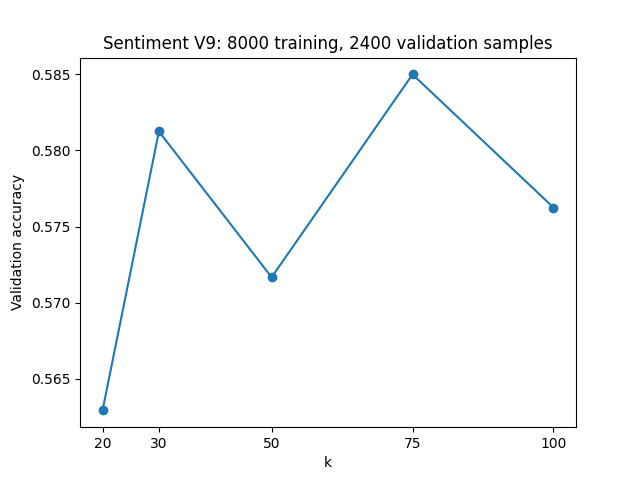

In [4]:
knn_result_dir = project_root / "results" / "knn"
plt.figure()
plt.plot(summary["k"], summary["validation_accuracy"], marker="o")
plt.xlabel("k")
plt.ylabel("Validation accuracy")
plt.title("Sentiment V9: 8000 training, 2400 validation samples")
plt.xticks(k_values)
plt.savefig(knn_result_dir / "knn_v9_sentiment_accuracy.png")
plt.show()


Finally, I compared the results to choose the best k.

In [5]:
best_accuracy = -1
for row in rows:
    # Values are ascending, so the smaller k wins an accuracy tie.
    if row["validation_accuracy"] > best_accuracy:
        best_k = row["k"]
        best_accuracy = row["validation_accuracy"]
print(f"Selected k: {best_k}, validation accuracy: {best_accuracy:.4%}")
print(f"V8 k=20 accuracy: {v8_baseline['validation_accuracy']:.4%}")
print("Validation accuracy improved:", best_accuracy > v8_baseline["validation_accuracy"] + 1e-15)
if best_k == 100:
    print("k=100 was the largest value tested.")
summary.to_csv(result_dir / "knn_v9_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(y_val)),
    "actual_label": y_val,
    "predicted_label": validation_predictions[best_k],
}).to_csv(result_dir / "knn_v9_validation.csv", index=False)


Selected k: 75, validation accuracy: 58.5000%
V8 k=20 accuracy: 56.2917%
Validation accuracy improved: True


I combined the selected sentiment predictions with the existing final image predictions for Kaggle.

In [6]:
submission_dir = project_root / "submission" / "knn"
final_submission = pd.read_csv(submission_dir / "submission_final_knn.csv")
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
_, _, _, image_test_ids = load_task("image")
assert final_submission.columns.tolist() == ["id", "label"]
assert len(final_submission) == 10000 and final_submission["id"].is_unique
assert len(image_test_ids) == 5000 and len(sentiment_test_ids) == 5000
assert set(final_submission["id"]) == set(image_test_ids) | set(sentiment_test_ids)
assert not final_submission.isna().any().any()
assert pd.api.types.is_integer_dtype(final_submission["label"])
assert final_submission.loc[final_submission["id"].isin(image_test_ids), "label"].between(0, 49).all()
assert final_submission.loc[final_submission["id"].isin(sentiment_test_ids), "label"].between(0, 2).all()

if best_k > 20:
    full_X_train, full_y_train, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
    assert full_X_train.shape == (12000, 768)
    assert len(full_y_train) == 12000 and sentiment_X_test.shape == (5000, 768)
    sentiment_clf = KNNClassifier(k=best_k, distance_fn=euclidean_distance, voting_method="majority")
    sentiment_clf.fit(full_X_train, full_y_train)
    print(f"Predicting 5000 sentiment test labels with k={best_k} and all 12000 labeled samples")
    start = perf_counter()
    sentiment_test_predictions = sentiment_clf.predict(sentiment_X_test)
    test_prediction_time = perf_counter() - start
    print(f"Sentiment test prediction time: {test_prediction_time:.6f} s")
    image_predictions = pd.DataFrame({"id": image_test_ids}).merge(
        final_submission, on="id", how="left", sort=False
    )
    assert len(image_predictions) == 5000 and not image_predictions.isna().any().any()
    sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
    predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
else:
    predictions = final_submission.copy()
    print("k=20 remains selected, so I reused the existing full-data predictions.")


Predicting 5000 sentiment test labels with k=75 and all 12000 labeled samples
Sentiment test prediction time: 353.872950 s


In [7]:
assert len(predictions) == 10000 and predictions["id"].is_unique
assert len(sample_submission) == 10000 and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])
assert submission["id"].isin(image_test_ids).sum() == 5000
assert submission["id"].isin(sentiment_test_ids).sum() == 5000
assert submission.loc[submission["id"].isin(image_test_ids), "label"].between(0, 49).all()
assert submission.loc[submission["id"].isin(sentiment_test_ids), "label"].between(0, 2).all()
submission_path = submission_dir / "submission_v9_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert len(saved_submission) == 10000 and saved_submission.columns.tolist() == ["id", "label"]
assert saved_submission["id"].is_unique and not saved_submission.isna().any().any()
assert pd.api.types.is_integer_dtype(saved_submission["label"])
for column in ["id", "label"]:
    assert saved_submission[column].tolist() == submission[column].tolist()
comparison = saved_submission.merge(
    final_submission, on="id", how="left", sort=False, suffixes=("_v9", "_final")
)
changed = comparison["label_v9"] != comparison["label_final"]
changed_predictions = int(changed.sum())
changed_image_predictions = int((changed & comparison["id"].isin(image_test_ids)).sum())
changed_sentiment_predictions = int((changed & comparison["id"].isin(sentiment_test_ids)).sum())
assert changed_image_predictions == 0
assert changed_predictions == changed_image_predictions + changed_sentiment_predictions
if best_k == 20:
    assert changed_predictions == 0
    for column in ["id", "label"]:
        assert saved_submission[column].tolist() == final_submission[column].tolist()
print("Saved and checked 10000 predictions in", submission_path)
print("Predictions identical to Final:", changed_predictions == 0)
print("Changed predictions:", changed_predictions)
print("Changed image predictions:", changed_image_predictions)
print("Changed sentiment predictions:", changed_sentiment_predictions)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v9_knn.csv
Predictions identical to Final: False
Changed predictions: 805
Changed image predictions: 0
Changed sentiment predictions: 805


In [8]:
tracker_path = knn_result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v9_row = {
    "version": "V9",
    "image_validation_accuracy": "",
    "sentiment_validation_accuracy": best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": submission_path.name,
    "notes": f"Tested sentiment k=20, 30, 50, 75, 100; selected k={best_k} using full validation. Full-data image predictions reused unchanged.",
}
matching = tracker["version"] == "V9"
if matching.any():
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v9_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v9_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle      submission_filename                                                                                                                                          notes
     V1                      0.21                         0.575                                   False                                                                                                                             k=3 and 1,000 training samples per dataset.
     V2                     0.215                         0.575               0.329                True    submission_v2_knn.csv                                                                                       Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
     V3                     0.215                         0.575                                   False    submission_v3_knn.csv                                                Compared